# Elkinematics Research and Experimentation Playground

This notebook serves as the central interactive sandbox and staging ground for the Elkinematics dysgraphia screening project.

### Workflow Sections:
1. **Environment and Centralized Config** - Load paths and hyperparameters from `scripts/config.py`.
2. **Centralized Model Builder** - Inspect and compile V0 (Baseline CNN), V1 (CNN+XAI), and V2 (Bi-LSTM).
3. **Data Loading and Discovery** - Scan and profile samples in `datasets/` and `val_datasets/`.
4. **Kinematic Feature Extraction** - Extract the 8 standard kinematic features (`delta_x`, `delta_y`, `pressure`, `tiltX`, `tiltY`, `velocity`, `acceleration`, `jerk`) and `latency`.
5. **Global Scaling and Preprocessing** - Normalize data using global Z-score scalers without leakage.
6. **Model Training and Tuning** - Train models with callbacks (EarlyStopping, ReduceLROnPlateau).
7. **Inference and Explainable AI (XAI)** - Predict risk scores and render stroke-level heatmaps.
8. **Evaluation and Performance Metrics** - Accuracy, Recall, Confusion Matrix, and ROC-AUC.
9. **Interactive Sandbox / Scratchpad** - Free-form sandbox for rapid prototyping.

## 1. Environment and Centralized Configuration

In [1]:
import sys
import os
from pathlib import Path

# Ensure project root and scripts directory are accessible
PROJECT_ROOT = Path(os.getcwd()).resolve()
SCRIPTS_DIR = PROJECT_ROOT / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

import config

print(f"Project Root: {config.PROJECT_ROOT}")
print(f"Max Timesteps: {config.MAX_TIMESTEPS} | Features: {config.FEATURES}")
print(f"Active Model V2 Path: {config.MODEL_PATHS['v2']}")
print(f"Scaler Path: {config.SCALER_PATH}")

Project Root: /Users/asthiseta/Project/somethinginmyeye
Max Timesteps: 500 | Features: 8
Active Model V2 Path: /Users/asthiseta/Project/somethinginmyeye/models/elkinematicV2.keras
Scaler Path: /Users/asthiseta/Project/somethinginmyeye/models/feature_scalers.npz


## 2. Centralized Model Builder and Architecture Summary

In [2]:
from model_builder import build_model, load_or_build_model

# Build and inspect our flagship V2 Bi-LSTM architecture
model_v2 = build_model(version="v2")
model_v2.summary()

Model: "elkinematics_v2_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ kinematics_input    │ (None, 500, 8)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_1            │ (None, 500, 128)  │     37,376 │ kinematics_input… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 500, 128)  │          0 │ bilstm_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_2            │ (None, 500, 64)   │     41,216 │ dropout_1[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latency_input       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 500, 64)   │          0 │ bilstm_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_latency      │ (None, 500, 1)    │          0 │ latency_input[0]… │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_modalities   │ (None, 500, 65)   │          0 │ dropout_2[0][0],  │
│ (Concatenate)       │                   │            │ repeat_latency[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ heatmap_output      │ (None, 500, 1)    │         66 │ concat_modalitie… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 78,658 (307.26 KB)

 Trainable params: 78,658 (307.26 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Data Loading and Discovery

In [3]:
import glob

train_files = glob.glob(os.path.join(config.DATASET_DIR, "*.csv"))
val_files = glob.glob(os.path.join(config.VAL_DATASET_DIR, "*.csv"))

train_normal = [f for f in train_files if "normal" in os.path.basename(f).lower()]
train_dyslexic = [f for f in train_files if ("dyslexia" in os.path.basename(f).lower() or "dysgraphia" in os.path.basename(f).lower())]

print(f"Training Set:   {len(train_files)} files (Normal: {len(train_normal)}, Dysgraphic/Dyslexic: {len(train_dyslexic)})")
print(f"Validation Set: {len(val_files)} files")

Training Set:   872 files (Normal: 436, Dysgraphic/Dyslexic: 436)
Validation Set: 218 files


## 4. Kinematic Feature Extraction (8 Kinematics Features and Latency)

In [ ]:
from universal_pipeline import extract_universal_features

sample_csv = os.path.join(config.SAMPLE_DIR, "sample_normal.csv")
if os.path.exists(sample_csv):
    sample_df = pd.read_csv(sample_csv)
    features_array = extract_universal_features(sample_df)
    print(f"Raw sample shape: {sample_df.shape}")
    print(f"Extracted feature tensor shape: {features_array.shape} (Timesteps x 9 internal features)")
    print("Feature columns:", config.FEATURE_NAMES + ["dt"])
else:
    print(f"Sample not found at {sample_csv}")

## 5. Global Scaling and Preprocessing Pipeline

In [4]:
from universal_pipeline import load_and_scale_universal, load_validation_with_train_scalers, get_v2_data

# 1. Load and compute global scalers on training data
print("Processing Training Cohort...")
X_train_seq_scaled, X_train_lat_scaled, y_train = load_and_scale_universal(
    data_dir=config.DATASET_DIR,
    scaler_save_path=config.SCALER_PATH
)

# 2. Transform validation cohort using frozen training scalers (Strict Hold-Out, No Leakage)
print("Processing Validation Cohort with Frozen Scalers...")
X_val_seq_scaled, X_val_lat_scaled, y_val = load_validation_with_train_scalers(
    data_dir=config.VAL_DATASET_DIR,
    scaler_path=config.SCALER_PATH
)

# 3. Format inputs for V2 Multi-Input Model
[X_train_v2_seq, X_train_v2_lat], y_train_td = get_v2_data(X_train_seq_scaled, X_train_lat_scaled, y_train)
[X_val_v2_seq, X_val_v2_lat], y_val_td = get_v2_data(X_val_seq_scaled, X_val_lat_scaled, y_val)

print(f"Scaled Training Sequences: {X_train_v2_seq.shape}")
print(f"Scaled Validation Sequences: {X_val_v2_seq.shape}")

Processing Training Cohort...
Saved global feature scalers to: /Users/asthiseta/Project/somethinginmyeye/models/feature_scalers.npz
Processing Validation Cohort with Frozen Scalers...
Scaled Training Sequences: (872, 500, 8)
Scaled Validation Sequences: (218, 500, 8)


## 6. Model Training and Fine-Tuning

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Build fresh compiled V2 model
experiment_model = build_model("v2", learning_rate=config.LEARNING_RATE)

early_stop = EarlyStopping(monitor='val_loss', patience=config.EARLY_STOPPING_PATIENCE, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=config.REDUCE_LR_PATIENCE, min_lr=config.MIN_LR, verbose=1)

# Optional: Set to True to train interactive experiment
TRAIN_EXPERIMENT = False

if TRAIN_EXPERIMENT:
    history = experiment_model.fit(
        [X_train_v2_seq, X_train_v2_lat], y_train_td,
        validation_data=([X_val_v2_seq, X_val_v2_lat], y_val_td),
        epochs=config.EPOCHS,
        batch_size=config.BATCH_SIZE,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )
else:
    print("Training skipped. Set TRAIN_EXPERIMENT = True to run full training cycle.")

## 7. Inference and Explainable AI (XAI) Heatmap Inspection

Loading existing V2 model weights from /Users/asthiseta/Project/somethinginmyeye/models/elkinematicV2.keras...
Sample: sample_normal.csv
Risk Score: 0.1623 -> Typical / Normal


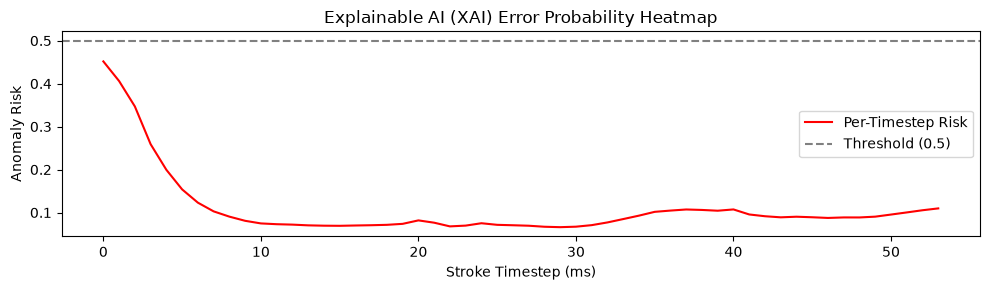

In [8]:
from universal_pipeline import unified_predict

# Load production trained model
prod_model = load_or_build_model("v2", filepath=config.MODEL_PATHS["v2"])

test_sample_path = os.path.join(config.SAMPLE_DIR, "sample_normal.csv")
if os.path.exists(test_sample_path):
    test_df = pd.read_csv(test_sample_path)
    score, heatmap = unified_predict(test_df, prod_model, version="v2", scaler_path=config.SCALER_PATH)
    
    print(f"Sample: {os.path.basename(test_sample_path)}")
    print(f"Risk Score: {score:.4f} -> {'Atypical / Dysgraphic' if score > 0.5 else 'Typical / Normal'}")
    
    # Plot XAI Risk Heatmap across stroke timesteps
    plt.figure(figsize=(10, 3))
    plt.plot(heatmap[:len(test_df)], color='red', label='Per-Timestep Risk')
    plt.axhline(0.5, color='gray', linestyle='--', label='Threshold (0.5)')
    plt.title("Explainable AI (XAI) Error Probability Heatmap")
    plt.xlabel("Stroke Timestep (ms)")
    plt.ylabel("Anomaly Risk")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"Test sample not found at {test_sample_path}")

## 8. Evaluation and Metrics

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

# Generate predictions on validation set
val_preds_td = prod_model.predict([X_val_v2_seq, X_val_v2_lat], verbose=0)
# Aggregate time-distributed output to sequence-level score
val_scores = np.mean(val_preds_td[:, :, 0], axis=1)
val_binary_preds = (val_scores > config.CLASSIFICATION_THRESHOLD).astype(int)

acc = accuracy_score(y_val, val_binary_preds)
rec = recall_score(y_val, val_binary_preds)
prec = precision_score(y_val, val_binary_preds)
f1 = f1_score(y_val, val_binary_preds)
auc = roc_auc_score(y_val, val_scores)

print("=" * 40)
print("MODEL V2 VALIDATION METRICS")
print("=" * 40)
print(f"Accuracy : {acc * 100:.2f}%")
print(f"Recall   : {rec * 100:.2f}%")
print(f"Precision: {prec * 100:.2f}%")
print(f"F1-Score : {f1 * 100:.2f}%")
print(f"ROC-AUC  : {auc:.4f}")
print("=" * 40)

## 9. Multi-Stream Specific Learning Disorder (SLD) Differential Screening
Evaluates handwriting samples through the dual-stream framework:
- **Kinematic Motoric Stream:** Bi-LSTM evaluating the 8 standard kinematic features for Motor Dysgraphia.
- **Orthographic & Reversal Stream:** Detects b/d and p/q mirror reversals and phonological spelling distance for Dyslexia.
- **Cognitive Initiation Latency:** Working memory threshold (> 1500 ms).
- **Multi-Attribute DSM-5 Categorizer:** Typical Development, Motor Dysgraphia, Dyslexia, Comorbid SLD.

In [ ]:
from sld_integrator import evaluate_sld_differential
import pandas as pd
import glob

# Test on sample cohort
sample_files = glob.glob(f"{config.SAMPLE_DIR}/*.csv")
print(f"Discovered {len(sample_files)} sample files for SLD differential evaluation:
")

for sample_file in sorted(sample_files):
    sample_name = sample_file.split("/")[-1]
    prompt_target = "bebek" if "bebek" in sample_name else "b"
    df_sample = pd.read_csv(sample_file)
    
    result = evaluate_sld_differential(
        df=df_sample,
        model=prod_model,
        expected_prompt=prompt_target
    )
    
    print(f"=== Sample: {sample_name} (Prompt: '{prompt_target}') ===")
    print(f"DSM-5 Diagnosis: {result['dsm5_diagnosis']}")
    print(f"Clinical Severity: {result['clinical_severity']}")
    print(f"Dysgraphia Risk: {result['dysgraphia_risk_percentage']}%")
    print(f"Dyslexia Risk: {result['dyslexia_risk_percentage']}%")
    print(f"Letter Reversal: {result['reversal_detected']} ({result['reversal_description']})")
    print(f"Cognitive Latency: {result['cognitive_latency_ms']} ms (Exceeds: {result['latency_exceeds_threshold']})
")


## 10. Interactive Sandbox / Scratchpad
Dedicated scratchpad area for free-form experimentation.

In [19]:
# ==============================================================================
# SECTION 10: CONTINUOUS FEATURE PROTOTYPE VECTOR (OPTION B)
# ==============================================================================

from typing import Any, Dict, List, Tuple
import numpy as np
import pandas as pd


# ------------------------------------------------------------------------------
# 1. 11-DIMENSIONAL CONTINUOUS FEATURE EXTRACTION
# ------------------------------------------------------------------------------
def extract_prototype_features(df: pd.DataFrame) -> np.ndarray:
    """Extracts an 11-dimensional continuous spatial feature vector:

    [aspect, cx, cy, top_h, mid_h, bot_h, left_v, mid_v, right_v, diag_pos,
    diag_neg]
    """
    x = df["x"].values
    y = df["y"].values

    w = max(x.max() - x.min(), 1.0)
    h = max(y.max() - y.min(), 1.0)

    # Normalize into unit bounding box [0, 1] x [0, 1]
    xn = (x - x.min()) / w
    yn = (y - y.min()) / h

    # 1. Aspect ratio: w/h normalized to [0, 1] (capped at 2.0)
    f_aspect = float(np.clip(w / (h + 1e-5), 0.0, 2.0) / 2.0)

    # 2. Centroid of mass
    f_cx = float(np.mean(xn))
    f_cy = float(np.mean(yn))

    # 3. Stroke directions
    dx = np.diff(xn)
    dy = np.diff(yn)
    angles = np.degrees(np.arctan2(np.abs(dy), np.abs(dx)))

    horiz_mask = angles < 35.0
    vert_mask = angles > 55.0
    diag_mask = (angles >= 35.0) & (angles <= 55.0)

    # Horizontal density across vertical bands (top, middle, bottom)
    mid_y = yn[:-1]
    f_top_h = (
        float(np.mean(horiz_mask & (mid_y < 0.33))) if len(mid_y) > 0 else 0.0
    )
    f_mid_h = (
        float(np.mean(horiz_mask & (mid_y >= 0.33) & (mid_y <= 0.67)))
        if len(mid_y) > 0
        else 0.0
    )
    f_bot_h = (
        float(np.mean(horiz_mask & (mid_y > 0.67))) if len(mid_y) > 0 else 0.0
    )

    # Vertical density across horizontal bands (left, middle, right)
    mid_x = xn[:-1]
    f_left_v = (
        float(np.mean(vert_mask & (mid_x < 0.35))) if len(mid_x) > 0 else 0.0
    )
    f_mid_v = (
        float(np.mean(vert_mask & (mid_x >= 0.35) & (mid_x <= 0.65)))
        if len(mid_x) > 0
        else 0.0
    )
    f_right_v = (
        float(np.mean(vert_mask & (mid_x > 0.65))) if len(mid_x) > 0 else 0.0
    )

    # Diagonal energies (screen coordinates: y grows downward)
    # Positive dx*dy = top-left to bottom-right (standard N diagonal)
    # Negative dx*dy = top-right to bottom-left (inverted Cyrillic И diagonal)
    if np.any(diag_mask):
        slope = dx[diag_mask] * dy[diag_mask]
        f_diag_pos = float(np.mean(slope > 0))
        f_diag_neg = float(np.mean(slope < 0))
    else:
        f_diag_pos, f_diag_neg = 0.0, 0.0

    return np.array([
        f_aspect,
        f_cx,
        f_cy,
        f_top_h,
        f_mid_h,
        f_bot_h,
        f_left_v,
        f_mid_v,
        f_right_v,
        f_diag_pos,
        f_diag_neg,
    ])


# ------------------------------------------------------------------------------
# 2. CANONICAL ALPHABET PROTOTYPES DICTIONARY
# Vector order: [aspect, cx, cy, top_h, mid_h, bot_h, left_v, mid_v, right_v, diag_pos, diag_neg]
# ------------------------------------------------------------------------------
ALPHABET_PROTOTYPES = {
    "A": np.array([
        0.40,
        0.50,
        0.45,
        0.05,
        0.45,
        0.00,
        0.25,
        0.00,
        0.15,
        0.50,
        0.40,
    ]),
    "B": np.array([
        0.35,
        0.50,
        0.50,
        0.25,
        0.25,
        0.25,
        0.50,
        0.00,
        0.20,
        0.00,
        0.00,
    ]),
    "C": np.array([
        0.40,
        0.40,
        0.50,
        0.35,
        0.00,
        0.35,
        0.35,
        0.00,
        0.00,
        0.00,
        0.00,
    ]),
    "D": np.array([
        0.40,
        0.50,
        0.50,
        0.30,
        0.00,
        0.30,
        0.50,
        0.00,
        0.25,
        0.00,
        0.00,
    ]),
    "E": np.array([
        0.35,
        0.45,
        0.50,
        0.35,
        0.30,
        0.35,
        0.50,
        0.00,
        0.00,
        0.00,
        0.00,
    ]),
    "F": np.array([
        0.35,
        0.45,
        0.40,
        0.40,
        0.35,
        0.00,
        0.50,
        0.00,
        0.00,
        0.00,
        0.00,
    ]),
    "H": np.array([
        0.40,
        0.50,
        0.50,
        0.00,
        0.40,
        0.00,
        0.45,
        0.00,
        0.45,
        0.00,
        0.00,
    ]),
    "I": np.array([
        0.15,
        0.50,
        0.50,
        0.20,
        0.00,
        0.20,
        0.00,
        0.70,
        0.00,
        0.00,
        0.00,
    ]),
    "L": np.array([
        0.35,
        0.45,
        0.60,
        0.00,
        0.00,
        0.50,
        0.50,
        0.00,
        0.00,
        0.00,
        0.00,
    ]),
    "M": np.array([
        0.55,
        0.50,
        0.50,
        0.00,
        0.00,
        0.00,
        0.40,
        0.00,
        0.40,
        0.40,
        0.40,
    ]),
    "N": np.array([
        0.40,
        0.50,
        0.50,
        0.00,
        0.00,
        0.00,
        0.45,
        0.00,
        0.45,
        0.60,
        0.00,
    ]),
    "O": np.array([
        0.45,
        0.50,
        0.50,
        0.30,
        0.00,
        0.30,
        0.30,
        0.00,
        0.30,
        0.00,
        0.00,
    ]),
    "P": np.array([
        0.35,
        0.45,
        0.40,
        0.25,
        0.25,
        0.00,
        0.55,
        0.00,
        0.20,
        0.00,
        0.00,
    ]),
    "T": np.array([
        0.40,
        0.50,
        0.35,
        0.60,
        0.00,
        0.00,
        0.00,
        0.60,
        0.00,
        0.00,
        0.00,
    ]),
    "U": np.array([
        0.40,
        0.50,
        0.55,
        0.00,
        0.00,
        0.30,
        0.40,
        0.00,
        0.40,
        0.00,
        0.00,
    ]),
    "V": np.array([
        0.40,
        0.50,
        0.55,
        0.00,
        0.00,
        0.00,
        0.15,
        0.00,
        0.15,
        0.45,
        0.45,
    ]),
    "Z": np.array([
        0.40,
        0.50,
        0.50,
        0.40,
        0.00,
        0.40,
        0.00,
        0.00,
        0.00,
        0.00,
        0.65,
    ]),
    # Lowercase & Mirror Twins
    "b": np.array([
        0.35,
        0.55,
        0.55,
        0.00,
        0.25,
        0.25,
        0.55,
        0.00,
        0.25,
        0.00,
        0.00,
    ]),
    "d": np.array([
        0.35,
        0.45,
        0.55,
        0.00,
        0.25,
        0.25,
        0.25,
        0.00,
        0.55,
        0.00,
        0.00,
    ]),
    "p": np.array([
        0.35,
        0.55,
        0.45,
        0.25,
        0.25,
        0.00,
        0.55,
        0.00,
        0.25,
        0.00,
        0.00,
    ]),
    "q": np.array([
        0.35,
        0.45,
        0.45,
        0.25,
        0.25,
        0.00,
        0.25,
        0.00,
        0.55,
        0.00,
        0.00,
    ]),
    "И": np.array([
        0.40,
        0.50,
        0.50,
        0.00,
        0.00,
        0.00,
        0.45,
        0.00,
        0.45,
        0.00,
        0.60,
    ]),  # Inverted N
}


# ------------------------------------------------------------------------------
# 3. GAUSSIAN RBF PROBABILITY MATCHER
# ------------------------------------------------------------------------------
def match_character_rbf(
    feats: np.ndarray, sigma: float = 0.35
) -> List[Tuple[str, float]]:
    """Calculates continuous Gaussian RBF probabilities across all prototypes."""
    scores = {}
    for char, proto in ALPHABET_PROTOTYPES.items():
        dist_sq = float(np.sum((feats - proto) ** 2))
        scores[char] = float(np.exp(-dist_sq / (2.0 * sigma**2)))

    total = sum(scores.values()) + 1e-9
    probs = [(char, round(s / total, 4)) for char, s in scores.items()]
    return sorted(probs, key=lambda x: x[1], reverse=True)


# ------------------------------------------------------------------------------
# 4. MULTI-STROKE SEGMENTATION & END-TO-END DECODER
# ------------------------------------------------------------------------------
def segment_strokes_into_characters(df: pd.DataFrame) -> List[Dict[str, Any]]:
    """Merges horizontally overlapping strokes into single character clusters."""
    touching = (
        df["touching"].astype(bool).values
        if "touching" in df.columns
        else np.ones(len(df), dtype=bool)
    )
    dt = df["time"].diff().fillna(1.0).values

    raw_strokes = []
    curr = []
    for i in range(len(df)):
        if touching[i]:
            if curr and dt[i] > 80.0:
                if len(curr) >= 3:
                    raw_strokes.append(pd.DataFrame(curr))
                curr = []
            curr.append(df.iloc[i])
        else:
            if len(curr) >= 3:
                raw_strokes.append(pd.DataFrame(curr))
            curr = []
    if len(curr) >= 3:
        raw_strokes.append(pd.DataFrame(curr))

    if not raw_strokes:
        return []

    character_clusters = []
    curr_char_strokes = [raw_strokes[0]]
    curr_box = [
        raw_strokes[0]["x"].min(),
        raw_strokes[0]["x"].max(),
        raw_strokes[0]["y"].min(),
        raw_strokes[0]["y"].max(),
    ]

    for s in raw_strokes[1:]:
        sx_min, sx_max = s["x"].min(), s["x"].max()
        char_width = max(curr_box[1] - curr_box[0], 10.0)
        overlap_x = min(curr_box[1], sx_max) - max(curr_box[0], sx_min)

        # Overlapping horizontal bounding box = same character (e.g. crossbar of 'A')
        if overlap_x > 0 or (sx_min - curr_box[1]) < (0.25 * char_width):
            curr_char_strokes.append(s)
            curr_box[0] = min(curr_box[0], sx_min)
            curr_box[1] = max(curr_box[1], sx_max)
            curr_box[2] = min(curr_box[2], s["y"].min())
            curr_box[3] = max(curr_box[3], s["y"].max())
        else:
            is_space = (sx_min - curr_box[1]) > (1.5 * char_width)
            character_clusters.append({
                "type": "character",
                "df": pd.concat(curr_char_strokes),
            })
            if is_space:
                character_clusters.append({"type": "space", "char": " "})
            curr_char_strokes = [s]
            curr_box = [sx_min, sx_max, s["y"].min(), s["y"].max()]

    if curr_char_strokes:
        character_clusters.append({
            "type": "character",
            "df": pd.concat(curr_char_strokes),
        })

    return character_clusters


def prototype_kin_coder(df: pd.DataFrame) -> Dict[str, Any]:
    """Decodes strokes into characters using Gaussian RBF prototype matching."""
    tokens = segment_strokes_into_characters(df)
    decoded_string = []
    details = []

    for tok in tokens:
        if tok["type"] == "space":
            decoded_string.append(" ")
        elif tok["type"] == "character":
            feats = extract_prototype_features(tok["df"])
            matches = match_character_rbf(feats)
            top_char, top_prob = matches[0]
            decoded_string.append(top_char)
            details.append({
                "winner": top_char,
                "confidence": top_prob,
                "top_candidates": matches[:3],
            })

    return {"text": "".join(decoded_string), "token_details": details}


# ------------------------------------------------------------------------------
# 5. TEST RUN ON SAMPLES
# ------------------------------------------------------------------------------
print("--- RUNNING CONTINUOUS PROTOTYPE KIN-CODER ---\n")

for sample_file in [
    "sample/sample_dyslexia.csv",
    "sample/sample_normal.csv",
    "sample/sample_normal_bebek.csv",
]:
    df_sample = pd.read_csv(sample_file)
    result = prototype_kin_coder(df_sample)
    print(f"File: {sample_file}")
    print(f"  Decoded Output: '{result['text']}'")
    for idx, d in enumerate(result["token_details"]):
        cands = ", ".join(
            [f"{c}: {p*100:.1f}%" for c, p in d["top_candidates"]]
        )
        print(f"  Char {idx+1}: {d['winner']} (Confidence: {cands})")
    print("-" * 55)

--- RUNNING CONTINUOUS PROTOTYPE KIN-CODER ---

File: sample/sample_dyslexia.csv
  Decoded Output: 'A'
  Char 1: A (Confidence: A: 41.5%, V: 15.4%, M: 9.2%)
-------------------------------------------------------
File: sample/sample_normal.csv
  Decoded Output: 'A'
  Char 1: A (Confidence: A: 22.1%, V: 21.3%, M: 15.7%)
-------------------------------------------------------
File: sample/sample_normal_bebek.csv
  Decoded Output: 'NVVV'
  Char 1: N (Confidence: N: 36.4%, A: 20.3%, V: 12.1%)
  Char 2: V (Confidence: V: 23.1%, A: 20.7%, M: 10.9%)
  Char 3: V (Confidence: V: 19.9%, A: 15.4%, И: 12.0%)
  Char 4: V (Confidence: V: 22.0%, И: 20.5%, Z: 15.7%)
-------------------------------------------------------
